# STEP 1 — Build FitzDataset (Target / Unlabeled)

In [ ]:
import os
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset


In [ ]:
class FitzDataset(Dataset):
    def __init__(self, img_root, csv_path, transform=None):
        """
        img_root : folder containing ALL unlabeled Fitz images
        csv_path : skin_binary.csv (image_name, skin_binary)
        """
        self.img_root = img_root
        self.transform = transform

        # load CSV
        df = pd.read_csv(csv_path)

        # normalize filenames
        df["image_name"] = df["image_name"].str.lower()

        # collect existing images on disk
        existing = set(
            f.lower()
            for f in os.listdir(img_root)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        )

        # keep only valid rows
        df = df[df["image_name"].isin(existing)]

        # safety checks
        assert df["image_name"].is_unique, "Duplicate image names found!"
        assert set(df["skin_binary"].unique()).issubset({0, 1}), "Invalid skin labels!"

        self.images = df["image_name"].tolist()
        self.labels = df["skin_binary"].tolist()

        print(f"[FitzDataset] Loaded {len(self.images)} images")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        img_path = os.path.join(self.img_root, img_name)

        img = Image.open(img_path).convert("RGB")

        if self.transform:
            img = self.transform(img)

        skin_label = int(self.labels[idx])

        return img, skin_label


In [ ]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])

fitz_dataset = FitzDataset(
    img_root="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/raw_unlabeled",
    csv_path="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/skin_binary.csv",
    transform=transform
)

print("Dataset length:", len(fitz_dataset))


[FitzDataset] Loaded 1966 images
Dataset length: 1966


# STEP 2 — Handle skin-tone imbalance (Target domain)
Weighted loss

In [ ]:
import torch
from collections import Counter

labels = fitz_dataset.labels
counts = Counter(labels)

print("Skin tone counts:", counts)

total = sum(counts.values())
class_weights = {
    cls: total / (len(counts) * count)
    for cls, count in counts.items()
}

print("Class weights:", class_weights)

weights_tensor = torch.tensor(
    [class_weights[0], class_weights[1]],
    dtype=torch.float
)


Skin tone counts: Counter({0.0: 1599, 1.0: 367})
Class weights: {0.0: 0.6147592245153221, 1.0: 2.678474114441417}


# STEP 3 — Merge ISIC + Fitz loaders

In [ ]:
from torchvision.datasets import ImageFolder
from torch.utils.data import Dataset

class ISICDataset(Dataset):
    def __init__(self, root, transform=None):
        self.dataset = ImageFolder(root=root, transform=transform)

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        img, label = self.dataset[idx]
        return img, label


In [ ]:
from torchvision import transforms

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor()
])


In [ ]:
from torch.utils.data import DataLoader

isic_dataset = ISICDataset(
    root="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged",
    transform=transform
)

isic_loader = DataLoader(
    isic_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    drop_last=True
)


In [ ]:
fitz_loader = DataLoader(
    fitz_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    drop_last=True
)


In [ ]:
xs, ys = next(iter(isic_loader))
xt, skin = next(iter(fitz_loader))

print("ISIC batch:", xs.shape, ys.shape)
print("Fitz batch:", xt.shape, skin.shape)


ISIC batch: torch.Size([32, 3, 224, 224]) torch.Size([32])
Fitz batch: torch.Size([32, 3, 224, 224]) torch.Size([32])


# STEP 4 — MDANN Training

In [ ]:
import torch
import torch.nn as nn
from torch.autograd import Function

class GradientReversal(Function):
    @staticmethod
    def forward(ctx, x, lambda_):
        ctx.lambda_ = lambda_
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return -ctx.lambda_ * grad_output, None


In [ ]:
def grl(x, lambda_):
    return GradientReversal.apply(x, lambda_)


In [ ]:
import torchvision.models as models

class MDANN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        backbone = models.mobilenet_v2(pretrained=True)
        self.encoder = backbone.features
        self.pool = nn.AdaptiveAvgPool2d(1)
        feat_dim = backbone.last_channel

        self.classifier = nn.Linear(feat_dim, num_classes)  # disease
        self.domain_disc = nn.Linear(feat_dim, 2)           # source vs target
        self.fairness_disc = nn.Linear(feat_dim, 2)         # skin tone

    def forward(self, x, lambda_domain=1.0, lambda_fair=1.0):
        feat = self.encoder(x)
        feat = self.pool(feat).flatten(1)

        disease_logits = self.classifier(feat)

        domain_logits = self.domain_disc(
            grl(feat, lambda_domain)
        )

        fairness_logits = self.fairness_disc(
            grl(feat, lambda_fair)
        )

        return disease_logits, domain_logits, fairness_logits


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
model = MDANN().to(device)

disease_criterion = nn.CrossEntropyLoss()

domain_criterion = nn.CrossEntropyLoss()

fairness_criterion = nn.CrossEntropyLoss(
    weight=weights_tensor.to(device)  # from STEP 2
)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 198MB/s]


In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


In [ ]:
def lambda_schedule(epoch, max_epoch):
    return min(1.0, epoch / max_epoch)


In [ ]:
def train_mdann(
    model,
    isic_loader,
    fitz_loader,
    epochs=30
):
    model.train()

    for epoch in range(epochs):
        lam = lambda_schedule(epoch, epochs)

        isic_iter = iter(isic_loader)
        fitz_iter = iter(fitz_loader)

        num_steps = min(len(isic_loader), len(fitz_loader))

        for step in range(num_steps):
            xs, ys = next(isic_iter)
            xt, skin = next(fitz_iter)

            xs, ys = xs.to(device), ys.to(device)
            xt, skin = xt.to(device), skin.to(device)

            # concatenate source + target
            x = torch.cat([xs, xt], dim=0)

            # domain labels
            domain_labels = torch.cat([
                torch.zeros(xs.size(0)),
                torch.ones(xt.size(0))
            ]).long().to(device)

            # forward (with scheduled λ)
            disease_logits, domain_logits, _ = model(
                x,
                lambda_domain=lam,
                lambda_fair=0.0   # fairness handled separately
            )

            # disease loss (source only)
            loss_disease = disease_criterion(
                disease_logits[:xs.size(0)], ys
            )

            # domain loss (source + target)
            loss_domain = domain_criterion(
                domain_logits, domain_labels
            )

            # -------- fairness path (target only) --------
            feat_t = model.encoder(xt)
            feat_t = model.pool(feat_t).flatten(1)

            fair_logits = model.fairness_disc(
                grl(feat_t, lam)
            )

            loss_fair = fairness_criterion(
                fair_logits, skin
            )
            # ---------------------------------------------

            beta = 0.3  # try 0.1, 0.3, 0.5
            loss = loss_disease + loss_domain + beta * loss_fair

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"λ={lam:.2f} | "
            f"Disease: {loss_disease.item():.3f} | "
            f"Domain: {loss_domain.item():.3f} | "
            f"Fair: {loss_fair.item():.3f}"
        )


In [ ]:
train_mdann(
    model,
    isic_loader,
    fitz_loader,
    epochs=30
)


Epoch 1/30 | λ=0.00 | Disease: 0.784 | Domain: 0.314 | Fair: 0.691
Epoch 2/30 | λ=0.03 | Disease: 0.787 | Domain: 0.355 | Fair: 0.677
Epoch 3/30 | λ=0.07 | Disease: 0.768 | Domain: 0.634 | Fair: 0.603
Epoch 4/30 | λ=0.10 | Disease: 0.722 | Domain: 3.330 | Fair: 0.630
Epoch 5/30 | λ=0.13 | Disease: 0.500 | Domain: 1.842 | Fair: 0.576
Epoch 6/30 | λ=0.17 | Disease: 0.783 | Domain: 2.163 | Fair: 0.646
Epoch 7/30 | λ=0.20 | Disease: 0.485 | Domain: 1.633 | Fair: 0.762
Epoch 8/30 | λ=0.23 | Disease: 0.714 | Domain: 2.383 | Fair: 1.148
Epoch 9/30 | λ=0.27 | Disease: 0.588 | Domain: 0.607 | Fair: 0.806
Epoch 10/30 | λ=0.30 | Disease: 0.611 | Domain: 1.457 | Fair: 0.690
Epoch 11/30 | λ=0.33 | Disease: 0.446 | Domain: 0.619 | Fair: 1.087
Epoch 12/30 | λ=0.37 | Disease: 0.733 | Domain: 1.485 | Fair: 1.500
Epoch 13/30 | λ=0.40 | Disease: 0.683 | Domain: 0.986 | Fair: 0.820
Epoch 14/30 | λ=0.43 | Disease: 0.881 | Domain: 1.486 | Fair: 0.943
Epoch 15/30 | λ=0.47 | Disease: 0.780 | Domain: 2.228 | F

In [ ]:
save_path = "/content/drive/MyDrive/mdann_isic_fitz_epoch30_2.pth"

torch.save({
    "epoch": 30,
    "model_state": model.state_dict(),
    "optimizer_state": optimizer.state_dict()
}, save_path)

print("Model saved to:", save_path)


Model saved to: /content/drive/MyDrive/mdann_isic_fitz_epoch30.pth


In [ ]:
eval_loader = isic_loader  # or ISIC_test_loader


In [ ]:
import numpy as np

def evaluate_7class(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            logits, _, _ = model(x, lambda_domain=0.0, lambda_fair=0.0)
            preds = torch.argmax(logits, dim=1)

            all_preds.append(preds.cpu())
            all_labels.append(y.cpu())

    return (
        np.concatenate(all_preds),
        np.concatenate(all_labels)
    )


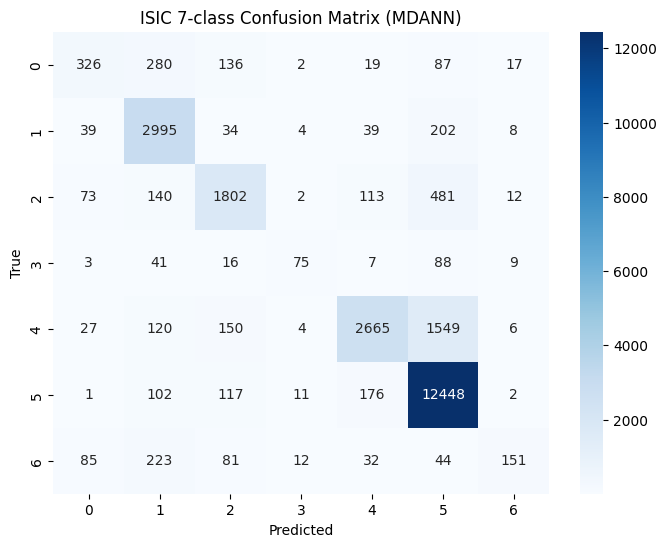

              precision    recall  f1-score   support

           0       0.59      0.38      0.46       867
           1       0.77      0.90      0.83      3321
           2       0.77      0.69      0.73      2623
           3       0.68      0.31      0.43       239
           4       0.87      0.59      0.70      4521
           5       0.84      0.97      0.90     12857
           6       0.74      0.24      0.36       628

    accuracy                           0.82     25056
   macro avg       0.75      0.58      0.63     25056
weighted avg       0.81      0.82      0.80     25056



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

y_pred, y_true = evaluate_7class(model, eval_loader)

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("ISIC 7-class Confusion Matrix (MDANN)")
plt.show()

print(classification_report(y_true, y_pred))


In [ ]:
def eval_fairness(model, loader):
    model.eval()
    correct = 0
    total = 0

    with torch.no_grad():
        for x, skin in loader:
            x = x.to(device)
            skin = skin.to(device)

            feat = model.encoder(x)
            feat = model.pool(feat).flatten(1)

            logits = model.fairness_disc(feat)
            preds = torch.argmax(logits, dim=1)

            correct += (preds == skin).sum().item()
            total += skin.size(0)

    return correct / total


In [ ]:
fair_acc = eval_fairness(model, fitz_loader)
print(f"Fairness (skin-tone) accuracy on Fitz: {fair_acc:.4f}")


Fairness (skin-tone) accuracy on Fitz: 0.6342


In [ ]:
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader

fitz_labeled_dataset = ImageFolder(
    root="/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected",
    transform=transform
)

fitz_labeled_loader = DataLoader(
    fitz_labeled_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Fitz labeled samples:", len(fitz_labeled_dataset))


Fitz labeled samples: 2059


In [ ]:
print(fitz_labeled_dataset.class_to_idx)
print(isic_dataset.dataset.class_to_idx)



{'ak': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'scc': 6}
{'ak': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'scc': 6}


In [ ]:
import numpy as np

def evaluate_disease(model, loader):
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x, y in loader:
            x = x.to(device)
            y = y.to(device)

            logits, _, _ = model(
                x,
                lambda_domain=0.0,
                lambda_fair=0.0
            )
            preds = torch.argmax(logits, dim=1)

            all_preds.append(preds.cpu())
            all_labels.append(y.cpu())

    return (
        np.concatenate(all_preds),
        np.concatenate(all_labels)
    )


In [ ]:
y_pred_fitz, y_true_fitz = evaluate_disease(
    model,
    fitz_labeled_loader
)


Fitz Target Performance (MDANN):
              precision    recall  f1-score   support

           0       0.19      0.07      0.10       175
           1       0.50      0.34      0.40       500
           2       0.07      0.32      0.11        69
           3       0.40      0.03      0.05        79
           4       0.33      0.29      0.31       500
           5       0.22      0.76      0.34       236
           6       0.54      0.08      0.14       500

    accuracy                           0.28      2059
   macro avg       0.32      0.27      0.21      2059
weighted avg       0.39      0.28      0.26      2059



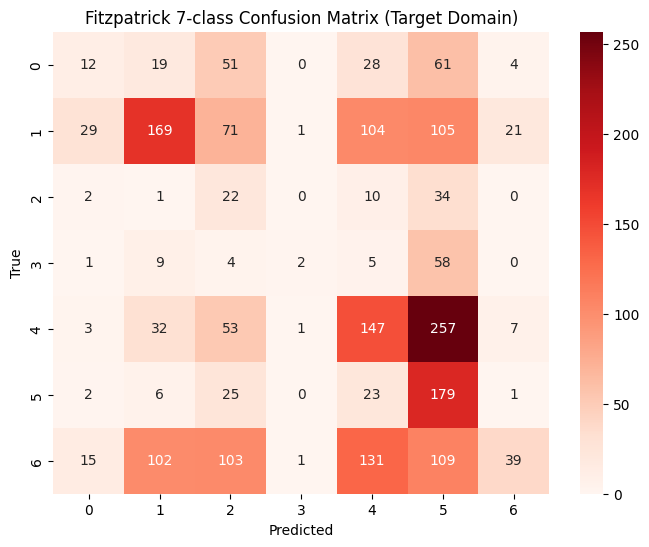

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

print("Fitz Target Performance (MDANN):")
print(classification_report(y_true_fitz, y_pred_fitz))

cm = confusion_matrix(y_true_fitz, y_pred_fitz)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Fitzpatrick 7-class Confusion Matrix (Target Domain)")
plt.show()


In [ ]:
print(fitz_labeled_dataset.class_to_idx)


{'ak': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'scc': 6}


In [ ]:
class_names = [
    "ak",   # 0
    "bcc",    # 1
    "bkl",   # 2
    "df", # 3
    "mel",   # 4
    "nv",    # 5
    "scc"   # 6
]


In [ ]:
import matplotlib.pyplot as plt
import torch
import random

def visualize_fitz_predictions(
    model,
    dataset,
    class_names,
    samples_per_class=3
):
    model.eval()

    # group indices by true class
    class_indices = {i: [] for i in range(len(class_names))}
    for idx, (_, label) in enumerate(dataset.samples):
        class_indices[label].append(idx)

    plt.figure(figsize=(samples_per_class * 4, len(class_names) * 3))

    plot_idx = 1

    for class_id, class_name in enumerate(class_names):
        if len(class_indices[class_id]) == 0:
            continue

        chosen = random.sample(
            class_indices[class_id],
            min(samples_per_class, len(class_indices[class_id]))
        )

        for idx in chosen:
            img, true_label = dataset[idx]
            x = img.unsqueeze(0).to(device)

            with torch.no_grad():
                logits, _, _ = model(
                    x,
                    lambda_domain=0.0,
                    lambda_fair=0.0
                )
                probs = torch.softmax(logits, dim=1)
                pred = torch.argmax(probs, dim=1).item()
                conf = probs[0, pred].item()

            plt.subplot(len(class_names), samples_per_class, plot_idx)
            plt.imshow(img.permute(1, 2, 0))
            plt.axis("off")

            title_color = "green" if pred == true_label else "red"
            plt.title(
                f"T: {class_names[true_label]}\n"
                f"P: {class_names[pred]} ({conf:.2f})",
                color=title_color,
                fontsize=9
            )

            plot_idx += 1

    plt.tight_layout()
    plt.show()


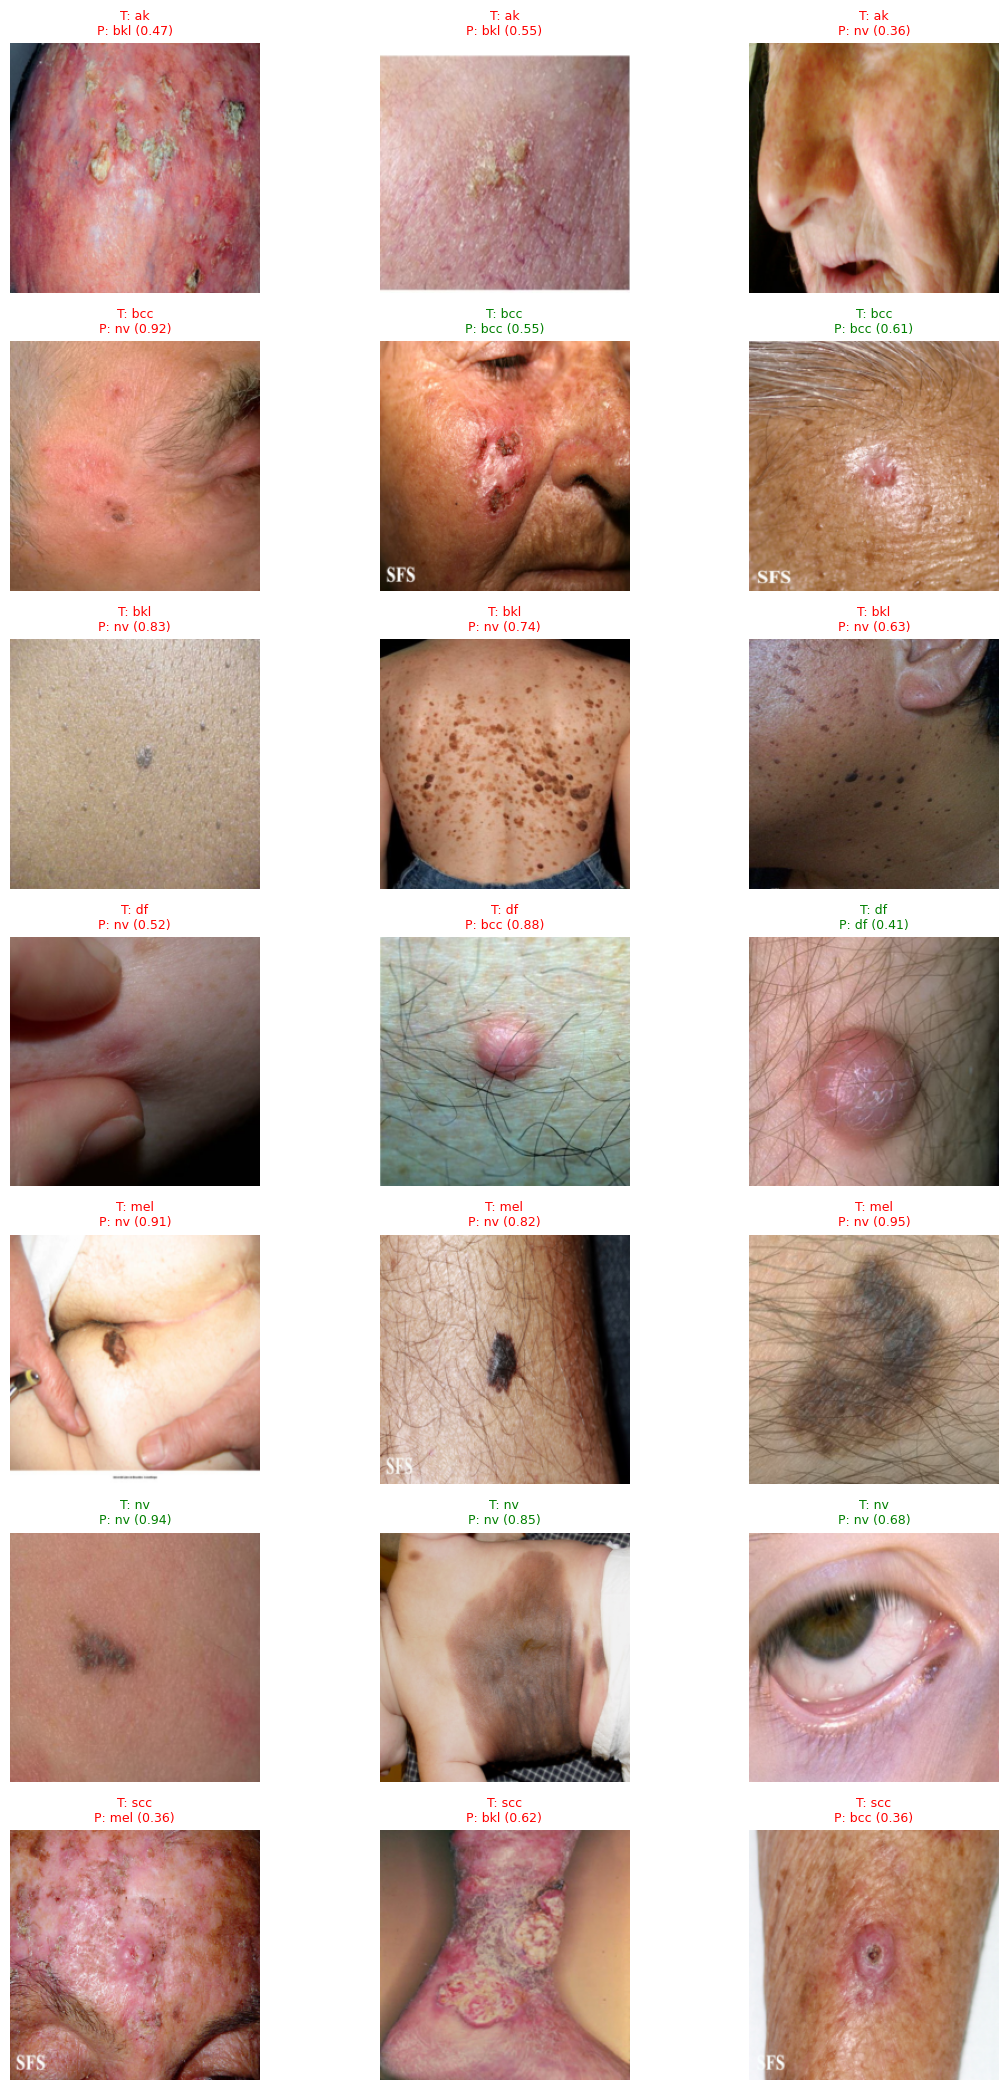

In [ ]:
visualize_fitz_predictions(
    model,
    fitz_labeled_dataset,
    class_names,
    samples_per_class=3
)


In [ ]:
def visualize_fitz_errors(model, dataset, class_names, max_samples=12):
    model.eval()
    errors = []

    for i in range(len(dataset)):
        img, true_label = dataset[i]
        x = img.unsqueeze(0).to(device)

        with torch.no_grad():
            logits, _, _ = model(x, 0.0, 0.0)
            pred = torch.argmax(logits, dim=1).item()

        if pred != true_label:
            errors.append((img, true_label, pred))

        if len(errors) >= max_samples:
            break

    plt.figure(figsize=(12, 4))
    for i, (img, t, p) in enumerate(errors):
        plt.subplot(1, max_samples, i + 1)
        plt.imshow(img.permute(1, 2, 0))
        plt.title(f"T:{class_names[t]}\nP:{class_names[p]}", color="red")
        plt.axis("off")

    plt.show()


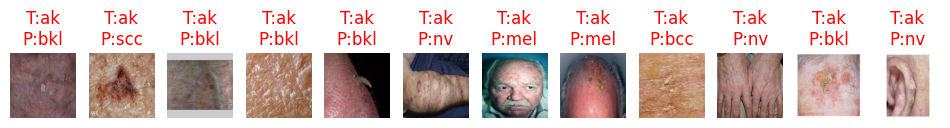

In [ ]:
visualize_fitz_errors(model, fitz_labeled_dataset, class_names)
